# Cleaning Data Chl-a Spatio-Temporal (Selat Sunda)

Notebook ini menyiapkan data bulanan chl-a hasil agregasi MODIS-Aqua (`MODISA_L3m_CHL`, 4 km, R2022.0) ke grid 0,25° supaya siap dipakai untuk pemodelan (baseline, model klasik, XGBoost, ConvLSTM).

**Prinsip yang dipegang**

1. **Target tidak pernah diimputasi.** Kolom `anom` hanya berisi nilai yang benar-benar teramati dan *reliable*. Evaluasi model nanti hanya boleh memakai kolom ini.
2. **Imputasi hanya untuk input** (`anom_input`), dan dibuat **kausal**: nilai di bulan *t* hanya diisi dengan informasi dari bulan *t* atau sebelumnya. Interpolasi linear biasa memakai bulan *t+1* sehingga membocorkan informasi masa depan ke model, jadi tidak dipakai.
3. **Semua statistik (klimatologi, ρ, ambang outlier) dihitung dari periode train saja** (`TRAIN_END`).
4. **Nilai ekstrem hanya ditandai**, tidak dibuang. Keputusan membuang atau tidak dibuat saat pemodelan (lihat `EXCLUDE_OUTLIERS`).

**Urutan langkah**

| No | Langkah | Output utama |
|---|---|---|
| 1 | Muat dan validasi struktur data | laporan validasi |
| 2 | Geometri grid: baris/kolom, mask darat, grid pesisir | `grid_meta` |
| 3 | Flag *reliable* dan transformasi log10 | `reliable`, `y` |
| 4 | Flag nilai ekstrem | `flag_outlier` |
| 5 | Klimatologi dari periode train + fallback | `y_clim`, `n_clim_years` |
| 6 | Anomali teramati (target) | `anom` |
| 7 | Imputasi kausal untuk input | `anom_input`, `impute_method` |
| 8 | Variabel eksogen: cek dan anomali | `*_anom` |
| 9 | Cek stabilitas MODIS-Aqua (tren, drift orbit) | grafik dan tabel |
| 10 | Simpan CSV, NPZ (untuk ConvLSTM), dan metadata | folder `data/processed/clean/` |

## 0. Konfigurasi

In [1]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

# ------------------ KONFIGURASI ------------------
REGION = 'selat_sunda'
TAG = '200301_202512_v1'
ROOT = Path(os.environ.get('THESIS_ROOT', r'D:/thesis'))

MONTHLY_PATH = ROOT / 'data' / 'processed' / 'chla' / f'chla_monthly_{TAG}.csv'
PANEL_PATH = ROOT / 'data' / 'processed' / 'model_dataset' / f'{REGION}_monthly_panel_{TAG}.csv'
GRID_CSV = ROOT / 'data' / 'metadata' / 'output_grid_target.csv'
OUT_DIR = ROOT / 'data' / 'processed' / 'clean'
FIG_DIR = ROOT / 'output' / 'figures' / 'cleaning'

TRAIN_END = pd.Timestamp('2018-12-01')   # train s.d. bulan ini (inklusif)
MIN_COVER = 0.25                         # fraksi piksel valid minimum agar 'reliable'
GRID_DEG = 0.25
MIN_CLIM_YEARS = 5                       # klimatologi dari < 5 tahun dianggap lemah -> fallback
OUTLIER_Z = 4.0                          # ambang robust z (log10) untuk flag nilai ekstrem
MAD_FLOOR = 0.05                         # batas bawah sebaran robust (log10) agar z tidak meledak
EXCLUDE_OUTLIERS = False                 # True -> nilai ber-flag diperlakukan sebagai missing
AQUA_DRIFT_START = pd.Timestamp('2022-01-01')  # awal drift orbit Aqua, untuk cek stabilitas
EXOG = {'sst_c': 'SST', 'u10_m_s': 'u10', 'v10_m_s': 'v10', 'wind_speed_m_s': 'Kec. angin'}
# --------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
report = {}   # ringkasan, disimpan ke JSON di akhir

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f'{name}_{REGION}_{TAG}.png', dpi=200, bbox_inches='tight')

for p in (MONTHLY_PATH, PANEL_PATH, GRID_CSV):
    print(('ADA   ' if p.is_file() else 'TIDAK ') + str(p))

ADA   D:\thesis\data\processed\chla\chla_monthly_200301_202512_v1.csv
ADA   D:\thesis\data\processed\model_dataset\selat_sunda_monthly_panel_200301_202512_v1.csv
ADA   D:\thesis\data\metadata\output_grid_target.csv


## 1. Muat dan validasi struktur data

Pengecekan: kolom wajib, duplikat, panel seimbang (semua grid ada di semua bulan), bulan berurutan tanpa lompatan, koordinat konsisten per grid, rentang nilai, serta konsistensi `n_valid_pixels`, `n_pixels_total`, `valid_pixel_fraction`, dan `chla_mg_m3`.

In [2]:
REQ = ['month', 'grid_id', 'lon', 'lat', 'chla_mg_m3', 'valid_pixel_fraction', 'n_valid_pixels', 'n_pixels_total']
raw = pd.read_csv(MONTHLY_PATH, parse_dates=['month'], dtype={'grid_id': str}, encoding='utf-8-sig')
missing_cols = [c for c in REQ if c not in raw.columns]
assert not missing_cols, f'Kolom wajib tidak ada: {missing_cols}'

# Pakai hanya grid terpilih bila file metadata grid ada
if GRID_CSV.is_file():
    ga = pd.read_csv(GRID_CSV, dtype={'grid_id': str}, encoding='utf-8-sig')
    if 'selected' in ga:
        keep = ga.loc[ga['selected'].astype(str).str.lower().str.strip().isin(['true', '1']), 'grid_id']
        n0 = raw.grid_id.nunique()
        raw = raw[raw.grid_id.isin(set(keep))]
        print(f'Grid terpilih dari metadata: {raw.grid_id.nunique()} dari {n0}')

m = raw[REQ].copy()
m['month'] = m.month.dt.to_period('M').dt.to_timestamp()   # normalisasi ke tanggal 1
m = m.sort_values(['grid_id', 'month']).reset_index(drop=True)

checks = {}
checks['baris'] = len(m)
checks['grid'] = m.grid_id.nunique()
checks['bulan'] = m.month.nunique()
checks['duplikat month-grid_id'] = int(m.duplicated(['month', 'grid_id']).sum())
checks['panel seimbang'] = len(m) == checks['grid'] * checks['bulan']
full_months = pd.date_range(m.month.min(), m.month.max(), freq='MS')
checks['bulan hilang dari rentang'] = len(full_months.difference(m.month.unique()))
coord_var = m.groupby('grid_id')[['lon', 'lat']].nunique()
checks['grid dengan koordinat tidak konsisten'] = int((coord_var > 1).any(axis=1).sum())
checks['chla <= 0'] = int((m.chla_mg_m3 <= 0).sum())
checks['fraksi di luar [0,1]'] = int((~m.valid_pixel_fraction.between(0, 1)).sum())
checks['n_valid > n_total'] = int((m.n_valid_pixels > m.n_pixels_total).sum())
frac_calc = m.n_valid_pixels / m.n_pixels_total.replace(0, np.nan)
checks['fraksi != n_valid/n_total (selisih > 0.01)'] = int(((frac_calc - m.valid_pixel_fraction).abs() > 0.01).sum())
checks['chla ada tapi n_valid = 0'] = int((m.chla_mg_m3.notna() & (m.n_valid_pixels == 0)).sum())
checks['chla NaN tapi n_valid > 0'] = int((m.chla_mg_m3.isna() & (m.n_valid_pixels > 0)).sum())

chk = pd.Series(checks, name='nilai').to_frame()
display(chk)
report['validasi'] = {k: (bool(v) if isinstance(v, (bool, np.bool_)) else int(v)) for k, v in checks.items()}

assert checks['duplikat month-grid_id'] == 0, 'Ada duplikat month-grid_id, perbaiki sumber data dulu.'
assert checks['grid dengan koordinat tidak konsisten'] == 0, 'Koordinat grid tidak konsisten.'

# Data dengan chl-a <= 0 tidak valid secara fisik -> jadikan missing
if checks['chla <= 0']:
    m.loc[m.chla_mg_m3 <= 0, 'chla_mg_m3'] = np.nan
    print('chl-a <= 0 diubah menjadi NaN.')

# Lengkapi panel bila ada grid-bulan yang hilang (baris baru = missing)
if not checks['panel seimbang'] or checks['bulan hilang dari rentang']:
    gi = m.groupby('grid_id')[['lon', 'lat']].first()
    idx = pd.MultiIndex.from_product([gi.index, full_months], names=['grid_id', 'month'])
    m = m.set_index(['grid_id', 'month']).reindex(idx).reset_index()
    m[['lon', 'lat']] = gi.loc[m.grid_id, ['lon', 'lat']].to_numpy()
    m[['n_valid_pixels', 'valid_pixel_fraction']] = m[['n_valid_pixels', 'valid_pixel_fraction']].fillna(0)
    m['n_pixels_total'] = m.groupby('grid_id').n_pixels_total.transform(lambda s: s.fillna(s.max()))
    print(f'Panel dilengkapi menjadi {len(m):,} baris.')

Grid terpilih dari metadata: 148 dari 148


,nilai
baris,40848
grid,148
bulan,276
duplikat month-grid_id,0
panel seimbang,True
bulan hilang dari rentang,0
grid dengan koordinat tidak konsisten,0
chla <= 0,0
"fraksi di luar [0,1]",0
n_valid > n_total,0


## 2. Geometri grid

Setiap grid diberi indeks baris (`row`, lintang) dan kolom (`col`, bujur) di kotak pembatas. Sel di kotak yang tidak punya grid dianggap **darat/di luar wilayah** (`sea_mask = False`). Grid **pesisir** ditandai bila punya tetangga darat atau tidak pernah mencapai jumlah piksel penuh, karena di sana nilai chl-a satelit rawan bias akibat kekeruhan.

Catatan orientasi array: baris 0 = lintang paling selatan (lintang naik ke atas). Saat menampilkan peta dengan `imshow`, pakai `origin='lower'`.

Kotak: 12 baris x 16 kolom = 192 sel | laut: 148 | darat/luar: 44
Grid pesisir: 42 | grid tidak pernah 36 piksel penuh: 11


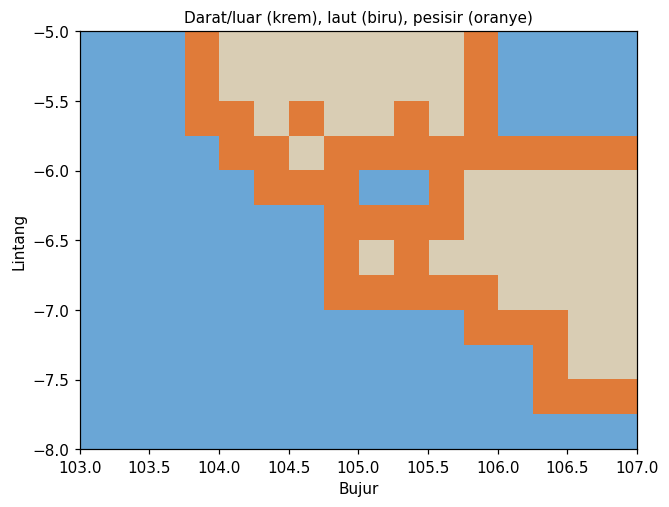

In [3]:
gi = m.groupby('grid_id', as_index=False).agg(lon=('lon', 'first'), lat=('lat', 'first'),
                                              n_pixels_total=('n_pixels_total', 'max'),
                                              max_valid_px=('n_valid_pixels', 'max'))
lons = np.round(np.arange(gi.lon.min(), gi.lon.max() + GRID_DEG / 2, GRID_DEG), 3)
lats = np.round(np.arange(gi.lat.min(), gi.lat.max() + GRID_DEG / 2, GRID_DEG), 3)
gi['col'] = np.rint((gi.lon - lons[0]) / GRID_DEG).astype(int)
gi['row'] = np.rint((gi.lat - lats[0]) / GRID_DEG).astype(int)
assert not gi.duplicated(['row', 'col']).any(), 'Dua grid jatuh di sel yang sama; cek GRID_DEG.'
NR, NC = len(lats), len(lons)

sea_mask = np.zeros((NR, NC), dtype=bool)
sea_mask[gi.row, gi.col] = True

# 8 tetangga (queen); di tepi kotak, sel luar dianggap bukan darat
OFFS = [(dr, dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr, dc) != (0, 0)]
pad = np.pad(sea_mask, 1, constant_values=True)
n_land_nb = sum((~pad[1 + dr:1 + dr + NR, 1 + dc:1 + dc + NC]).astype(int) for dr, dc in OFFS)
gi['n_land_neighbors'] = n_land_nb[gi.row, gi.col]
full_px = int(gi.n_pixels_total.median())
gi['flag_coastal'] = (gi.n_land_neighbors > 0) | (gi.max_valid_px < full_px)

print(f'Kotak: {NR} baris x {NC} kolom = {NR * NC} sel | laut: {sea_mask.sum()} | darat/luar: {(~sea_mask).sum()}')
print(f'Grid pesisir: {int(gi.flag_coastal.sum())} | grid tidak pernah {full_px} piksel penuh: {int((gi.max_valid_px < full_px).sum())}')

m = m.merge(gi[['grid_id', 'row', 'col', 'flag_coastal']], on='grid_id', how='left')
m['cal_month'] = m.month.dt.month
m['split'] = np.where(m.month <= TRAIN_END, 'train', 'test')
report['grid'] = {'n_rows': NR, 'n_cols': NC, 'n_sea': int(sea_mask.sum()), 'n_coastal': int(gi.flag_coastal.sum())}

fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
show = sea_mask.astype(int)
show[gi.row[gi.flag_coastal], gi.col[gi.flag_coastal]] = 2
ax.imshow(show, vmin=0, vmax=2, origin='lower', cmap=plt.matplotlib.colors.ListedColormap(['#d9cdb4', '#6aa6d6', '#e07b39']),
               extent=[lons[0] - GRID_DEG / 2, lons[-1] + GRID_DEG / 2, lats[0] - GRID_DEG / 2, lats[-1] + GRID_DEG / 2])
ax.set_title('Darat/luar (krem), laut (biru), pesisir (oranye)', fontsize=10)
ax.set_xlabel('Bujur'); ax.set_ylabel('Lintang'); ax.grid(False)
save_fig(fig, 'mask_grid'); plt.show()

## 3. Flag *reliable* dan transformasi log10

Grid-bulan dianggap **reliable** bila chl-a ada dan fraksi piksel valid ≥ `MIN_COVER`. Yang tidak reliable (termasuk yang hanya punya sedikit piksel) diperlakukan sebagai **missing**. Target pemodelan adalah `y = log10(chl-a)` karena distribusi chl-a sangat miring ke kanan.

In [5]:
m['reliable'] = m.chla_mg_m3.notna() & (m.valid_pixel_fraction >= MIN_COVER)
m['y'] = np.where(m.reliable, np.log10(m.chla_mg_m3), np.nan)

rel = pd.DataFrame({
    'chl-a tidak NaN': m.chla_mg_m3.notna().mean(),
    'reliable (semua)': m.reliable.mean(),
    'reliable (train)': m.loc[m.split == 'train', 'reliable'].mean(),
    'reliable (test)': m.loc[m.split == 'test', 'reliable'].mean(),
}, index=['proporsi']).T
display(rel.style.format('{:.1%}'))
report['reliable_share'] = float(m.reliable.mean())

,proporsi
chl-a tidak NaN,97.2%
reliable (semua),95.0%
reliable (train),95.0%
reliable (test),94.9%


## 4. Flag nilai ekstrem

Nilai ekstrem dideteksi dengan **robust z-score** di ruang log10, relatif terhadap median dan MAD grid tersebut pada bulan kalender yang sama (dihitung dari train saja):

`z = (y − median) / max(1.4826 × MAD, MAD_FLOOR)`

Grid-bulan dengan |z| > `OUTLIER_Z` diberi `flag_outlier = True`. Nilainya **tidak diubah**. Tabel di bawah menunjukkan apakah nilai ekstrem terkumpul di grid pesisir, yang menjadi indikasi bias kekeruhan pada algoritma chl-a MODIS.

In [6]:
trn = m[(m.split == 'train') & m.reliable]
stat = trn.groupby(['grid_id', 'cal_month']).y.agg(
    med='median', mad=lambda s: (s - s.median()).abs().median(), n='size').reset_index()
# Fallback bila satu grid-bulan kalender punya < 3 tahun: pakai statistik grid keseluruhan
stat_g = trn.groupby('grid_id').y.agg(med_g='median', mad_g=lambda s: (s - s.median()).abs().median()).reset_index()
m = m.drop(columns=['_med', '_scale'], errors='ignore').merge(stat, on=['grid_id', 'cal_month'], how='left').merge(stat_g, on='grid_id', how='left')
weak = m.n.isna() | (m.n < 3)
m['_med'] = np.where(weak, m.med_g, m.med)
m['_scale'] = np.maximum(1.4826 * np.where(weak, m.mad_g, m.mad), MAD_FLOOR)
m['robust_z'] = (m.y - m._med) / m._scale
m['flag_outlier'] = m.robust_z.abs() > OUTLIER_Z
m = m.drop(columns=['med', 'mad', 'n', 'med_g', 'mad_g', '_med', '_scale'])

n_out = int(m.flag_outlier.sum())
print(f'Grid-bulan ber-flag ekstrem: {n_out:,} ({n_out / max(m.reliable.sum(), 1):.2%} dari data reliable)')
tab = (m[m.reliable].groupby('flag_coastal')
       .agg(n_reliable=('y', 'size'), n_outlier=('flag_outlier', 'sum'),
            chla_p99=('chla_mg_m3', lambda s: s.quantile(.99)), chla_max=('chla_mg_m3', 'max')))
tab['proporsi_outlier'] = tab.n_outlier / tab.n_reliable
tab.index = tab.index.map({True: 'pesisir', False: 'lepas pantai'})
display(tab.round(3))

top = (m[m.flag_outlier].sort_values('robust_z', key=np.abs, ascending=False)
       [['month', 'grid_id', 'lat', 'lon', 'flag_coastal', 'chla_mg_m3', 'valid_pixel_fraction', 'robust_z']].head(10))
display(top.round({'chla_mg_m3': 3, 'valid_pixel_fraction': 3, 'robust_z': 2}))
report['outlier'] = {'n_flag': n_out, 'n_flag_pesisir': int(m.flag_outlier[m.flag_coastal].sum())}

if EXCLUDE_OUTLIERS:
    m.loc[m.flag_outlier, 'y'] = np.nan
    m['reliable'] = m.reliable & ~m.flag_outlier
    print('EXCLUDE_OUTLIERS=True: nilai ber-flag diperlakukan sebagai missing.')

Grid-bulan ber-flag ekstrem: 1,208 (3.11% dari data reliable)


,n_reliable,n_outlier,chla_p99,chla_max,proporsi_outlier
flag_coastal,,,,,
lepas pantai,27998,907,2.652,15.760,0.032
pesisir,10805,301,4.546,29.782,0.028


,month,grid_id,lat,lon,flag_coastal,chla_mg_m3,valid_pixel_fraction,robust_z
5770,2023-11-01,G025_R382_C1134,-5.625,103.625,False,9.283,1.000,29.68
33719,2006-12-01,G025_R390_C1138,-7.625,104.625,False,3.113,1.000,27.84
5722,2019-11-01,G025_R382_C1134,-5.625,103.625,False,5.998,1.000,26.48
1030,2019-11-01,G025_R380_C1135,-5.125,103.875,True,29.782,0.556,24.38
17639,2023-12-01,G025_R385_C1139,-6.375,104.875,True,2.866,1.000,22.52
9358,2023-11-01,G025_R383_C1135,-5.875,103.875,False,8.859,1.000,21.44
3010,2023-11-01,G025_R381_C1133,-5.375,103.375,False,5.031,0.917,20.94
37187,2019-12-01,G025_R391_C1134,-7.875,103.625,False,0.978,0.833,20.81
21455,2019-12-01,G025_R387_C1133,-6.875,103.375,False,1.035,0.972,20.78
13846,2006-11-01,G025_R384_C1137,-6.125,104.375,True,7.363,1.000,20.55


## 5. Klimatologi dari periode train

`y_clim` = rata-rata `y` per (grid, bulan kalender) dari data train yang reliable. Karena bulan berawan (Oktober–Februari) sering kosong, sebagian klimatologi hanya dihitung dari sedikit tahun. Bila jumlah tahun < `MIN_CLIM_YEARS`, dipakai **fallback**: rata-rata bulan kalender m−1, m, m+1 (melingkar) di grid yang sama. Kolom `clim_fallback` menandai sel yang memakai fallback.

Pasangan grid-bulan kalender: 1,776 | memakai fallback (< 5 tahun): 0


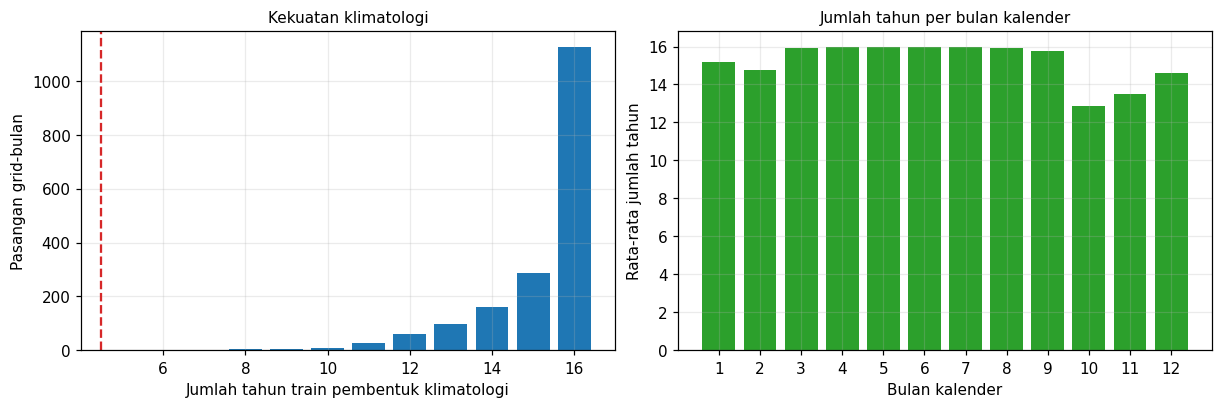

In [7]:
def climatology(frame, col):
    # Kembalikan tabel (grid_id, cal_month) -> clim, n_years, fallback (dari train saja)
    t = frame[(frame.split == 'train') & frame[col].notna()]
    base = t.groupby(['grid_id', 'cal_month'])[col].agg(clim='mean', n_years='size')
    full = pd.MultiIndex.from_product([frame.grid_id.unique(), range(1, 13)], names=['grid_id', 'cal_month'])
    base = base.reindex(full).reset_index()
    base['n_years'] = base.n_years.fillna(0).astype(int)
    # rata-rata 3 bulan melingkar
    sums = t.groupby(['grid_id', 'cal_month'])[col].sum().reindex(full, fill_value=0).unstack()
    cnts = t.groupby(['grid_id', 'cal_month'])[col].size().reindex(full, fill_value=0).unstack()
    roll_s = sum(np.roll(sums.to_numpy(), k, axis=1) for k in (-1, 0, 1))
    roll_c = sum(np.roll(cnts.to_numpy(), k, axis=1) for k in (-1, 0, 1))
    roll = pd.DataFrame(roll_s / np.where(roll_c == 0, np.nan, roll_c), index=sums.index, columns=sums.columns)
    roll.columns.name = None
    roll = roll.reset_index().melt(id_vars='grid_id', var_name='cal_month', value_name='clim3')
    roll['cal_month'] = roll.cal_month.astype(int)
    base = base.merge(roll, on=['grid_id', 'cal_month'], how='left')
    gmean = t.groupby('grid_id')[col].mean().rename('clim_all')
    base = base.merge(gmean, on='grid_id', how='left')
    base['fallback'] = base.n_years < MIN_CLIM_YEARS
    base['clim'] = np.where(base.fallback, base.clim3, base.clim)
    base['clim'] = base.clim.fillna(base.clim_all)   # cadangan terakhir: rata-rata grid
    return base[['grid_id', 'cal_month', 'clim', 'n_years', 'fallback']]

clim_y = climatology(m, 'y').rename(columns={'clim': 'y_clim', 'n_years': 'n_clim_years', 'fallback': 'clim_fallback'})
m = m.drop(columns=['y_clim', 'n_clim_years', 'clim_fallback'], errors='ignore').merge(clim_y, on=['grid_id', 'cal_month'], how='left')
assert m.y_clim.notna().all(), 'Masih ada klimatologi kosong.'

print(f'Pasangan grid-bulan kalender: {len(clim_y):,} | memakai fallback (< {MIN_CLIM_YEARS} tahun): {int(clim_y.clim_fallback.sum())}')
dist = clim_y.n_clim_years.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].bar(dist.index, dist.values, color='tab:blue'); axes[0].axvline(MIN_CLIM_YEARS - .5, color='tab:red', ls='--')
axes[0].set_xlabel('Jumlah tahun train pembentuk klimatologi'); axes[0].set_ylabel('Pasangan grid-bulan')
axes[0].set_title('Kekuatan klimatologi', fontsize=10)
mon = clim_y.groupby('cal_month').n_clim_years.mean()
axes[1].bar(mon.index, mon.values, color='tab:green'); axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel('Bulan kalender'); axes[1].set_ylabel('Rata-rata jumlah tahun')
axes[1].set_title('Jumlah tahun per bulan kalender', fontsize=10)
save_fig(fig, 'kekuatan_klimatologi'); plt.show()
report['klimatologi'] = {'n_pasangan': len(clim_y), 'n_fallback': int(clim_y.clim_fallback.sum())}

## 6. Anomali teramati (target)

`anom = y − y_clim`, **hanya** untuk grid-bulan reliable. Kolom ini adalah target pemodelan dan dasar evaluasi. Jangan pernah mengevaluasi model pada nilai hasil imputasi.

ρ (koefisien *damped persistence*) dihitung dari train: regresi tanpa intersep anomali bulan *t* terhadap bulan *t−1*, hanya pada pasangan yang keduanya teramati. Nilai ini dipakai di langkah imputasi berikutnya.

In [8]:
m['anom'] = np.where(m.reliable, m.y - m.y_clim, np.nan)
m = m.sort_values(['grid_id', 'month']).reset_index(drop=True)
m['_a_lag1'] = m.groupby('grid_id').anom.shift(1)
pair = m[(m.split == 'train') & m.anom.notna() & m._a_lag1.notna()]
RHO = float((pair.anom * pair._a_lag1).sum() / (pair._a_lag1 ** 2).sum())
m = m.drop(columns='_a_lag1')
print(f'rho (train) = {RHO:.3f} dari {len(pair):,} pasangan')
print(f"Rata-rata anomali: train = {m.loc[m.split == 'train', 'anom'].mean():+.4f}, test = {m.loc[m.split == 'test', 'anom'].mean():+.4f}")
report['rho_train'] = RHO

rho (train) = 0.515 dari 25,657 pasangan
Rata-rata anomali: train = +0.0000, test = +0.0397


## 7. Imputasi kausal untuk input (`anom_input`)

Urutan pengisian untuk setiap grid-bulan yang tidak teramati:

1. **Tetangga spasial (bulan yang sama):** rata-rata `anom` teramati dari 8 grid tetangga. Hanya memakai nilai asli, bukan hasil imputasi. Ini kausal karena di bulan yang sama.
2. **Damped carry-forward:** bila tidak ada tetangga yang teramati, `anom_input(t) = ρ × anom_input(t−1)`. Untuk celah panjang, nilainya meluruh ke 0 (kembali ke klimatologi), sama seperti logika *damped persistence*.
3. **Nol (klimatologi):** untuk bulan pertama yang tidak punya bulan sebelumnya.

Kolom `impute_method` mencatat sumber setiap nilai: `observed`, `spatial`, `temporal`, `climatology`, atau `land` (khusus di array NPZ).

In [9]:
months = np.sort(m.month.unique())
T = len(months)
t_idx = pd.Series(np.arange(T), index=pd.DatetimeIndex(months))

def to_cube(col, fill=np.nan):
    cube = np.full((T, NR, NC), fill, dtype=float)
    cube[t_idx.loc[m.month].to_numpy(), m.row.to_numpy(), m.col.to_numpy()] = m[col].to_numpy(dtype=float)
    return cube

A_obs = to_cube('anom')                  # NaN = tidak teramati atau darat
obs = ~np.isnan(A_obs)

# Langkah 1: rata-rata tetangga yang teramati
padA = np.pad(A_obs, ((0, 0), (1, 1), (1, 1)), constant_values=np.nan)
nb_sum = np.zeros_like(A_obs); nb_cnt = np.zeros_like(A_obs)
for dr, dc in OFFS:
    sl = padA[:, 1 + dr:1 + dr + NR, 1 + dc:1 + dc + NC]
    nb_sum += np.nan_to_num(sl); nb_cnt += ~np.isnan(sl)
nb_mean = np.where(nb_cnt > 0, nb_sum / np.where(nb_cnt == 0, 1, nb_cnt), np.nan)

A_in = A_obs.copy()
method = np.full(A_obs.shape, 'land', dtype=object)
method[:, sea_mask] = 'missing'
method[obs] = 'observed'

use_sp = ~obs & ~np.isnan(nb_mean) & sea_mask[None]
A_in[use_sp] = nb_mean[use_sp]; method[use_sp] = 'spatial'

# Langkah 2 dan 3: damped carry-forward (kausal), lalu nol
for t in range(T):
    need = np.isnan(A_in[t]) & sea_mask
    if not need.any():
        continue
    if t == 0:
        A_in[t][need] = 0.0; method[t][need] = 'climatology'
    else:
        A_in[t][need] = RHO * A_in[t - 1][need]; method[t][need] = 'temporal'

assert not np.isnan(A_in[:, sea_mask]).any(), 'Masih ada sel laut kosong.'
A_in[:, ~sea_mask] = 0.0   # darat diisi 0; selalu pakai bersama sea_mask/obs_mask

r_, c_ = m.row.to_numpy(), m.col.to_numpy(); ti = t_idx.loc[m.month].to_numpy()
m['anom_input'] = A_in[ti, r_, c_]
m['impute_method'] = method[ti, r_, c_]
m['y_input'] = m.y_clim + m.anom_input

summ = m.impute_method.value_counts().rename('n').to_frame()
summ['proporsi'] = summ.n / len(m)
display(summ.style.format({'proporsi': '{:.2%}'}))
report['imputasi'] = summ.n.astype(int).to_dict()

,n,proporsi
impute_method,,
observed,38803,94.99%
spatial,1759,4.31%
temporal,286,0.70%


### Validasi imputasi (pseudo-missing)

Untuk menilai kualitas imputasi secara jujur, sebagian nilai **teramati** di periode train disembunyikan secara acak, diimputasi dengan aturan yang sama, lalu dibandingkan dengan nilai aslinya. Hasilnya dibandingkan dengan pilihan paling sederhana (isi 0 = klimatologi). Ini menjadi bahan yang bisa dilaporkan di bab metodologi.

In [10]:
rng = np.random.default_rng(42)
train_t = np.where(pd.DatetimeIndex(months) <= TRAIN_END)[0]
cand = np.argwhere(obs[train_t])
pick = cand[rng.choice(len(cand), size=min(2000, len(cand)), replace=False)]
tt, rr, cc = train_t[pick[:, 0]], pick[:, 1], pick[:, 2]
truth = A_obs[tt, rr, cc]

A_mask = A_obs.copy(); A_mask[tt, rr, cc] = np.nan
padM = np.pad(A_mask, ((0, 0), (1, 1), (1, 1)), constant_values=np.nan)
s_ = np.zeros(len(tt)); n_ = np.zeros(len(tt))
for dr, dc in OFFS:
    v = padM[tt, rr + 1 + dr, cc + 1 + dc]; s_ += np.nan_to_num(v); n_ += ~np.isnan(v)
sp = np.where(n_ > 0, s_ / np.where(n_ == 0, 1, n_), np.nan)
prev = np.where(tt > 0, A_in[np.maximum(tt - 1, 0), rr, cc], 0.0)
tmp = RHO * prev
imp = np.where(np.isnan(sp), tmp, sp)

def rmse(a, b): return float(np.sqrt(np.nanmean((a - b) ** 2)))
val = pd.DataFrame({
    'RMSE (log10)': [rmse(truth, imp), rmse(truth[~np.isnan(sp)], sp[~np.isnan(sp)]), rmse(truth, tmp), rmse(truth, 0 * truth)],
    'n': [len(truth), int((~np.isnan(sp)).sum()), len(truth), len(truth)]},
    index=['skema penuh', 'hanya tetangga', 'hanya damped (rho x t-1)', 'isi 0 (klimatologi)'])
display(val.round(4))
report['validasi_imputasi_rmse'] = val['RMSE (log10)'].round(4).to_dict()

,RMSE (log10),n
skema penuh,0.0846,2000
hanya tetangga,0.0843,1997
hanya damped (rho x t-1),0.1929,2000
isi 0 (klimatologi),0.2197,2000


## 8. Variabel eksogen

Panel eksogen (SST, u10, v10, kecepatan angin) dicek kelengkapan dan rentangnya, lalu dihitung anomalinya dengan klimatologi train yang sama. Bila ada yang kosong, diisi dengan klimatologi (anomali 0) dan ditandai. Kecepatan angin juga dibandingkan dengan √(u10² + v10²): rata-rata bulanan kecepatan selalu ≥ besar vektor rata-rata, jadi rasionya harus ≥ 1.

In [11]:
exog_cols = []
if PANEL_PATH.is_file():
    px = pd.read_csv(PANEL_PATH, parse_dates=['month'], dtype={'grid_id': str}, encoding='utf-8-sig')
    px['month'] = px.month.dt.to_period('M').dt.to_timestamp()
    exog_cols = [c for c in EXOG if c in px.columns]
    px = px[['month', 'grid_id', *exog_cols]].drop_duplicates(['month', 'grid_id'])
    m = m.drop(columns=exog_cols, errors='ignore').merge(px, on=['month', 'grid_id'], how='left')

    ex = m[exog_cols].describe(percentiles=[.01, .5, .99]).T
    ex['missing'] = m[exog_cols].isna().mean()
    display(ex.round(3))
    if {'u10_m_s', 'v10_m_s', 'wind_speed_m_s'} <= set(exog_cols):
        ratio = m.wind_speed_m_s / np.hypot(m.u10_m_s, m.v10_m_s)
        print(f'Rasio kecepatan / |vektor rata-rata|: median {ratio.median():.2f}, '
              f'proporsi < 0.99: {(ratio < .99).mean():.2%} (harus mendekati 0)')

    for c in exog_cols:
        cl = climatology(m, c).rename(columns={'clim': f'{c}_clim'})[['grid_id', 'cal_month', f'{c}_clim']]
        m = m.drop(columns=[f'{c}_clim'], errors='ignore').merge(cl, on=['grid_id', 'cal_month'], how='left')
        m[f'{c}_anom'] = m[c] - m[f'{c}_clim']
        m[f'{c}_imputed'] = m[c].isna()
        m[f'{c}_anom'] = m[f'{c}_anom'].fillna(0.0)
    report['eksogen_missing'] = m[exog_cols].isna().mean().round(4).to_dict()
else:
    print('Panel eksogen tidak ditemukan; langkah ini dilewati.')

,count,mean,std,min,1%,50%,99%,max,missing
sst_c,40848.0,28.724,0.973,23.074,25.230,28.876,30.314,30.947,0.0
u10_m_s,40848.0,-1.187,3.818,-8.862,-7.905,-1.139,6.775,8.098,0.0
v10_m_s,40848.0,1.364,2.376,-5.146,-3.519,1.106,5.929,7.656,0.0
wind_speed_m_s,40848.0,4.123,2.549,0.002,0.291,3.690,9.257,10.051,0.0


Rasio kecepatan / |vektor rata-rata|: median 1.00, proporsi < 0.99: 0.00% (harus mendekati 0)


## 9. Cek stabilitas MODIS-Aqua

Data berasal dari satu sensor (MODIS-Aqua, R2022.0), jadi tidak ada lompatan antar-sensor. Ada dua hal yang tetap perlu dicek:

- **Tren jangka panjang.** Klimatologi dari 2003–2018 dipakai untuk 2019–2025. Bila ada tren, anomali di periode uji akan bias (rata-ratanya jauh dari 0).
- **Drift orbit Aqua.** Sejak sekitar 2022 orbit Aqua bergeser sehingga waktu lintasnya makin sore. Ini bisa mengubah geometri pengamatan dan cakupan data. Rata-rata anomali dan ketersediaan sebelum dan sesudah `AQUA_DRIFT_START` dibandingkan.

Pengecekan memakai anomali **teramati** rata-rata regional (bulan dengan ≥ 50% grid teramati).

,rata-rata anomali regional,ketersediaan reliable,n bulan
train (<= TRAIN_END),-0.0021,0.9503,189.0
test (> TRAIN_END),0.0355,0.9491,83.0
sebelum 2022,0.0053,0.9510,225.0
sejak 2022,0.0289,0.9451,47.0


Tren anomali regional: -0.0093 log10/dekade (95% CI kira-kira [-0.1064, +0.0878], dikoreksi autokorelasi; setara -2.1% chl-a per dekade)


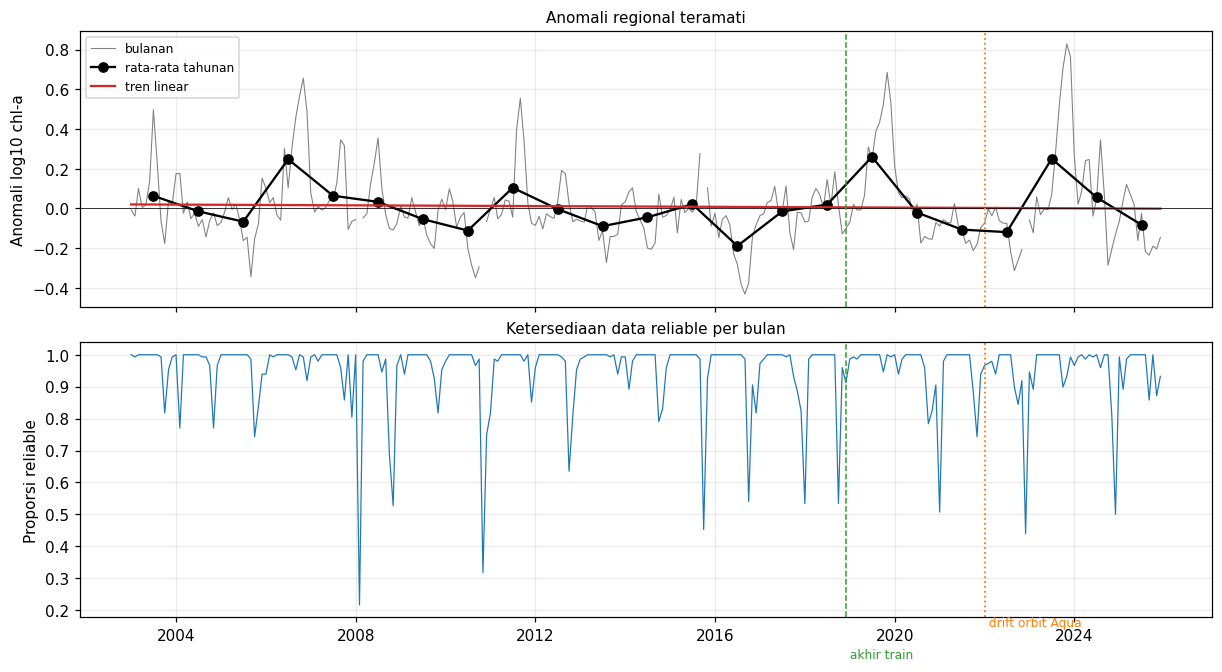

In [12]:
A_df = m.pivot(index='month', columns='grid_id', values='anom')
reg = A_df.mean(axis=1).where(A_df.notna().mean(axis=1) >= .5)
avail = m.groupby('month').reliable.mean()
yr = reg.groupby(reg.index.year).mean()

d = reg.dropna()
x = (d.index.year + (d.index.month - 1) / 12).to_numpy()
X = np.c_[np.ones(len(x)), x - x.mean()]
beta, *_ = np.linalg.lstsq(X, d.to_numpy(), rcond=None)
resid = d.to_numpy() - X @ beta
r1 = pd.Series(resid).autocorr(1)
neff = len(d) * (1 - r1) / (1 + r1)
se = np.sqrt(resid.var(ddof=2) / ((x - x.mean()) ** 2).sum() * len(d) / max(neff, 3))
slope_dec = beta[1] * 10

periods = {'train (<= TRAIN_END)': reg.index <= TRAIN_END,
           'test (> TRAIN_END)': reg.index > TRAIN_END,
           f'sebelum {AQUA_DRIFT_START:%Y}': reg.index < AQUA_DRIFT_START,
           f'sejak {AQUA_DRIFT_START:%Y}': reg.index >= AQUA_DRIFT_START}
stab = pd.DataFrame({k: {'rata-rata anomali regional': reg[v].mean(),
                         'ketersediaan reliable': avail[v].mean(),
                         'n bulan': int(reg[v].notna().sum())} for k, v in periods.items()}).T
display(stab.round(4))
print(f'Tren anomali regional: {slope_dec:+.4f} log10/dekade '
      f'(95% CI kira-kira [{(beta[1] - 1.96 * se) * 10:+.4f}, {(beta[1] + 1.96 * se) * 10:+.4f}], '
      f'dikoreksi autokorelasi; setara {10 ** slope_dec - 1:+.1%} chl-a per dekade)')

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].plot(reg.index, reg, lw=.7, color='gray', label='bulanan')
axes[0].plot(pd.to_datetime(yr.index.astype(str) + '-07-01'), yr, marker='o', color='black', label='rata-rata tahunan')
axes[0].plot(d.index, X @ beta, color='tab:red', lw=1.5, label='tren linear')
axes[0].axhline(0, color='k', lw=.5); axes[0].set_ylabel('Anomali log10 chl-a'); axes[0].legend(fontsize=8)
axes[0].set_title('Anomali regional teramati', fontsize=10)
axes[1].plot(avail.index, avail, lw=.8, color='tab:blue'); axes[1].set_ylabel('Proporsi reliable')
axes[1].set_title('Ketersediaan data reliable per bulan', fontsize=10)
for ax in axes:
    ax.axvline(TRAIN_END, color='tab:green', ls='--', lw=1); ax.axvline(AQUA_DRIFT_START, color='tab:orange', ls=':', lw=1.2)
axes[1].text(TRAIN_END, .05, ' akhir train', color='tab:green', fontsize=8)
axes[1].text(AQUA_DRIFT_START, .15, ' drift orbit Aqua', color='tab:orange', fontsize=8)
save_fig(fig, 'stabilitas_modis_aqua'); plt.show()
report['stabilitas'] = {'tren_log10_per_dekade': float(slope_dec), 'tren_se_per_dekade': float(se * 10),
                        **{f'mean_anom_{k}': float(v) for k, v in stab['rata-rata anomali regional'].items()}}

**Cara membaca hasil di atas**

- Bila rata-rata anomali periode test kecil (misalnya |nilai| < 0,03 log10, sekitar 7%) dan CI tren mencakup 0, klimatologi train aman dipakai.
- Bila tren signifikan, ada dua pilihan: (a) tambahkan tren linear ke klimatologi, atau (b) cukup laporkan sebagai keterbatasan. Pilihan (a) lebih tepat bila selisih rata-rata anomali test cukup besar.
- Penurunan ketersediaan setelah 2022 menandakan dampak drift orbit Aqua dan perlu disebut di bab keterbatasan.

## 10. Simpan output

| File | Isi | Dipakai untuk |
|---|---|---|
| `clean_panel_*.csv` | Satu baris per grid-bulan, semua kolom bersih | baseline, GSTAR, XGBoost |
| `grid_meta_*.csv` | Koordinat, baris/kolom, flag pesisir | matriks bobot spasial (GSTAR) |
| `climatology_*.csv` | Klimatologi chl-a per grid × bulan kalender | rekonstruksi prediksi ke nilai chl-a |
| `cube_*.npz` | Array 3D (waktu × lintang × bujur) + mask | ConvLSTM |
| `cleaning_report_*.json` | Konfigurasi dan ringkasan | dokumentasi metodologi |

Kolom kunci di panel bersih: `anom` (target, NaN bila tidak teramati), `anom_input` (input lengkap), `impute_method`, `reliable`, `flag_outlier`, `flag_coastal`, `y_clim`, `clim_fallback`, `split`.

In [13]:
base_cols = ['month', 'grid_id', 'row', 'col', 'lat', 'lon', 'cal_month', 'split',
             'chla_mg_m3', 'valid_pixel_fraction', 'n_valid_pixels', 'n_pixels_total',
             'reliable', 'flag_outlier', 'robust_z', 'flag_coastal',
             'y', 'y_clim', 'n_clim_years', 'clim_fallback', 'anom', 'anom_input', 'y_input', 'impute_method']
exog_out = [c for e in exog_cols for c in (e, f'{e}_clim', f'{e}_anom', f'{e}_imputed')]
clean = m[base_cols + exog_out].sort_values(['month', 'grid_id']).reset_index(drop=True)

suffix = f'{REGION}_{TAG}'
p_panel = OUT_DIR / f'clean_panel_{suffix}.csv'
p_grid = OUT_DIR / f'grid_meta_{suffix}.csv'
p_clim = OUT_DIR / f'climatology_{suffix}.csv'
p_cube = OUT_DIR / f'cube_{suffix}.npz'
p_rep = OUT_DIR / f'cleaning_report_{suffix}.json'

clean.to_csv(p_panel, index=False, encoding='utf-8-sig')
gi[['grid_id', 'row', 'col', 'lat', 'lon', 'n_pixels_total', 'max_valid_px', 'n_land_neighbors', 'flag_coastal']] \
    .sort_values(['row', 'col']).to_csv(p_grid, index=False, encoding='utf-8-sig')
clim_y.to_csv(p_clim, index=False, encoding='utf-8-sig')

cube = {
    'months': np.array([pd.Timestamp(t).strftime('%Y-%m') for t in months]),
    'lats': lats, 'lons': lons,
    'grid_id': np.array([[''] * NC for _ in range(NR)], dtype=object),
    'sea_mask': sea_mask,
    'train_mask': np.array(pd.DatetimeIndex(months) <= TRAIN_END),
    'obs_mask': obs,                             # True = anomali teramati (boleh dipakai di loss/evaluasi)
    'anom_obs': A_obs.astype(np.float32),        # target; NaN bila tidak teramati atau darat
    'anom_input': A_in.astype(np.float32),       # input lengkap; darat = 0
    'impute_code': np.select([method == 'observed', method == 'spatial', method == 'temporal', method == 'climatology'],
                             [0, 1, 2, 3], 9).astype(np.int8),   # 9 = darat
    'y_clim': to_cube('y_clim').astype(np.float32),
    'flag_outlier': np.nan_to_num(to_cube('flag_outlier'), nan=0).astype(bool),
    'coastal_mask': np.zeros((NR, NC), dtype=bool),
}
cube['grid_id'][gi.row, gi.col] = gi.grid_id
cube['grid_id'] = cube['grid_id'].astype(str)
cube['coastal_mask'][gi.row[gi.flag_coastal], gi.col[gi.flag_coastal]] = True
for c in exog_cols:
    cube[f'{c}_anom'] = np.nan_to_num(to_cube(f'{c}_anom'), nan=0.0).astype(np.float32)
np.savez_compressed(p_cube, **cube)

report.update({
    'region': REGION, 'tag': TAG, 'sumber': 'MODIS-Aqua MODISA_L3m_CHL harian 4 km R2022.0, agregasi bulanan grid 0.25 derajat',
    'config': {'TRAIN_END': f'{TRAIN_END:%Y-%m}', 'MIN_COVER': MIN_COVER, 'GRID_DEG': GRID_DEG,
               'MIN_CLIM_YEARS': MIN_CLIM_YEARS, 'OUTLIER_Z': OUTLIER_Z, 'MAD_FLOOR': MAD_FLOOR,
               'EXCLUDE_OUTLIERS': EXCLUDE_OUTLIERS},
    'n_bulan': int(T), 'n_grid': int(len(gi)),
    'orientasi_cube': 'axis0=waktu, axis1=lintang naik (row 0 = paling selatan), axis2=bujur naik',
    'impute_code': {'0': 'observed', '1': 'spatial', '2': 'temporal (rho x t-1)', '3': 'climatology', '9': 'darat'},
})
with open(p_rep, 'w', encoding='utf-8') as f:
    json.dump(report, f, indent=2, ensure_ascii=False, default=str)

for p in (p_panel, p_grid, p_clim, p_cube, p_rep):
    print(f'{p.stat().st_size / 1e6:7.2f} MB  {p}')

  20.07 MB  D:\thesis\data\processed\clean\clean_panel_selat_sunda_200301_202512_v1.csv
   0.01 MB  D:\thesis\data\processed\clean\grid_meta_selat_sunda_200301_202512_v1.csv
   0.09 MB  D:\thesis\data\processed\clean\climatology_selat_sunda_200301_202512_v1.csv
   0.95 MB  D:\thesis\data\processed\clean\cube_selat_sunda_200301_202512_v1.npz
   0.00 MB  D:\thesis\data\processed\clean\cleaning_report_selat_sunda_200301_202512_v1.json


## 11. Cek akhir

Verifikasi bahwa output konsisten: target tidak ikut terimputasi, input lengkap di semua sel laut, dan file NPZ bisa dibaca ulang dengan bentuk yang benar.

In [14]:
chk = clean
assert chk.loc[chk.impute_method != 'observed', 'anom'].isna().all(), 'Target ikut terisi imputasi!'
assert chk.anom_input.notna().all(), 'Input masih ada yang kosong.'
assert np.allclose(chk.loc[chk.impute_method == 'observed', 'anom'], chk.loc[chk.impute_method == 'observed', 'anom_input'])

z = np.load(p_cube, allow_pickle=False)
print({k: z[k].shape for k in ['anom_obs', 'anom_input', 'obs_mask', 'sea_mask', 'y_clim']})
assert z['anom_input'].shape == (T, NR, NC)
assert not np.isnan(z['anom_input']).any()
assert (z['obs_mask'] <= z['sea_mask'][None]).all(), 'Ada sel teramati di darat.'
print('Semua cek lolos. Data siap dipakai untuk pemodelan.')

# Contoh cara memakai di tahap pemodelan:
# z = np.load(p_cube)
# X = np.stack([z['anom_input'], z['obs_mask'].astype('float32')], axis=1)   # channel: anomali + mask teramati
# target = np.nan_to_num(z['anom_obs']); loss_mask = z['obs_mask']             # loss hanya di sel teramati

{'anom_obs': (276, 12, 16), 'anom_input': (276, 12, 16), 'obs_mask': (276, 12, 16), 'sea_mask': (12, 16), 'y_clim': (276, 12, 16)}
Semua cek lolos. Data siap dipakai untuk pemodelan.
